### Workshop1 - Adding Sunglasses to Your Passport Photo Using OpenCV
### NAME : SADHANA S
### REG.NO : 212224230234


Text(0.5, 1.0, 'Face')

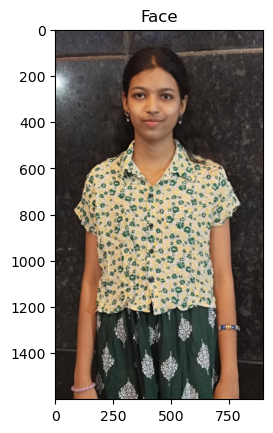

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the Face Image
faceImage = cv2.imread(r"C:\Users\admin\Downloads\mypic.jpeg")
plt.imshow(faceImage[:,:,::-1]); plt.title("Face")

In [2]:
#resized_faceImage.shape
faceImage.shape

(1600, 900, 3)

Text(0.5, 1.0, 'glassPNG')

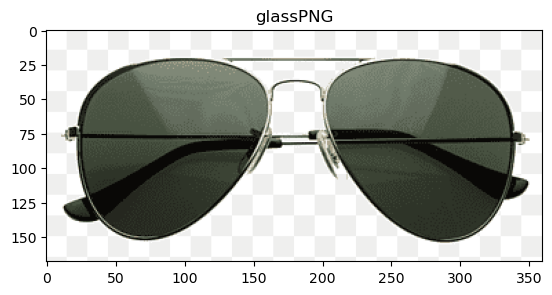

In [3]:
# Load the Sunglass image with Alpha channel
glassPNG = cv2.imread(r"C:\Users\admin\Downloads\sun.png", -1)
plt.imshow(glassPNG[:,:,::-1]); plt.title("glassPNG")

In [4]:
glassPNG.shape

(168, 360, 3)

In [5]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG, (190, 50))
print("image Dimension = {}".format(glassPNG.shape))

image Dimension = (50, 190, 3)


In [7]:
print(glassPNG.shape)

(50, 190, 3)


Text(0.5, 1.0, 'Sunglass Alpha channel (Created)')

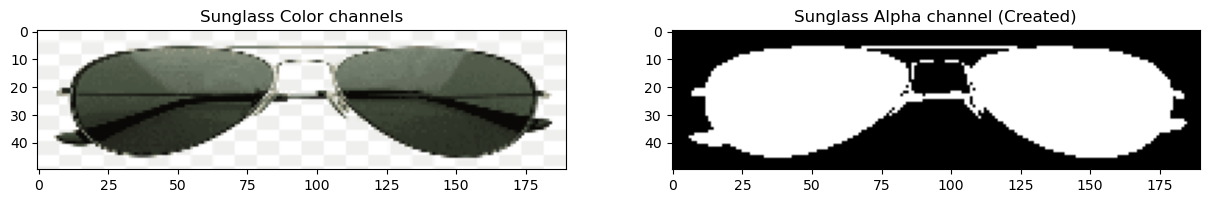

In [18]:
# Separate the Color channels
glassBGR = glassPNG[:,:,0:3]

# Create a STRICTER mask (anything lighter than 200 becomes black)
gray_glass = cv2.cvtColor(glassPNG, cv2.COLOR_BGR2GRAY)
_, glassMask1 = cv2.threshold(gray_glass, 200, 255, cv2.THRESH_BINARY_INV)

# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121); plt.imshow(glassBGR[:,:,::-1]); plt.title('Sunglass Color channels')
plt.subplot(122); plt.imshow(glassMask1, cmap='gray'); plt.title('Sunglass Alpha channel (Created)')

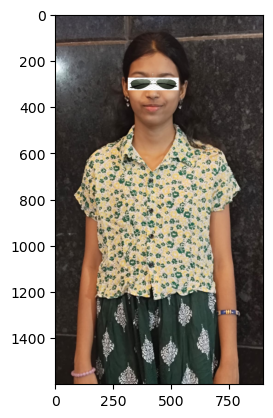

In [20]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# 1. Make them slightly WIDER (Width: 220, Height: 55)
glassPNG_resized = cv2.resize(glassPNG, (220, 55))
glassBGR_resized = glassPNG_resized[:,:,0:3]

# 2. Move UP slightly and center (Y: 275 to 330, X: 315 to 535)
faceWithGlassesNaive[275:330, 315:535] = glassBGR_resized

plt.imshow(faceWithGlassesNaive[:,:,::-1])

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

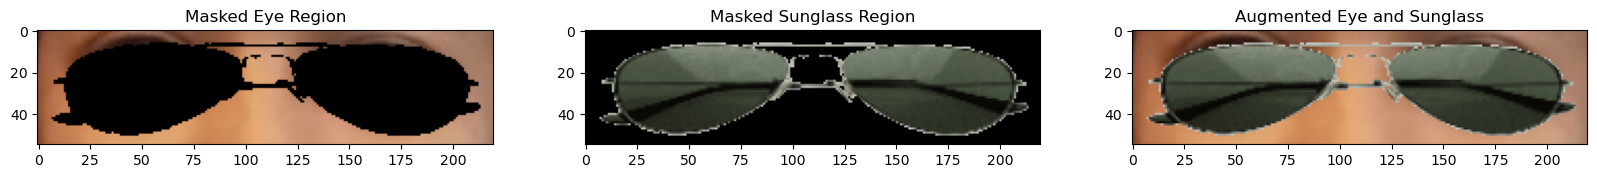

In [22]:
# 1. Resize the glasses to the new perfect size
glassPNG_resized = cv2.resize(glassPNG, (220, 55))
glassBGR_resized = glassPNG_resized[:,:,0:3]

# 2. Re-create the mask to match the new size
gray_glass = cv2.cvtColor(glassPNG_resized, cv2.COLOR_BGR2GRAY)
_, glassMask1_resized = cv2.threshold(gray_glass, 200, 255, cv2.THRESH_BINARY_INV)

# 3. Create the 3-channel mask
glassMask = cv2.merge((glassMask1_resized, glassMask1_resized, glassMask1_resized))
glassMask = np.uint8(glassMask/255)

# 4. Make a copy of the face and get the NEW Eye ROI
faceWithGlassesArithmetic = faceImage.copy()
# We use the new coordinates: Y: 275 to 330, X: 315 to 535
eyeROI = faceWithGlassesArithmetic[275:330, 315:535]

# 5. Blend them
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))
maskedGlass = cv2.multiply(glassBGR_resized, glassMask)
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# 6. Display the results
plt.figure(figsize=[20,20])
plt.subplot(131); plt.imshow(maskedEye[:,:,::-1]); plt.title("Masked Eye Region")
plt.subplot(132); plt.imshow(maskedGlass[:,:,::-1]); plt.title("Masked Sunglass Region")
plt.subplot(133); plt.imshow(eyeRoiFinal[:,:,::-1]); plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

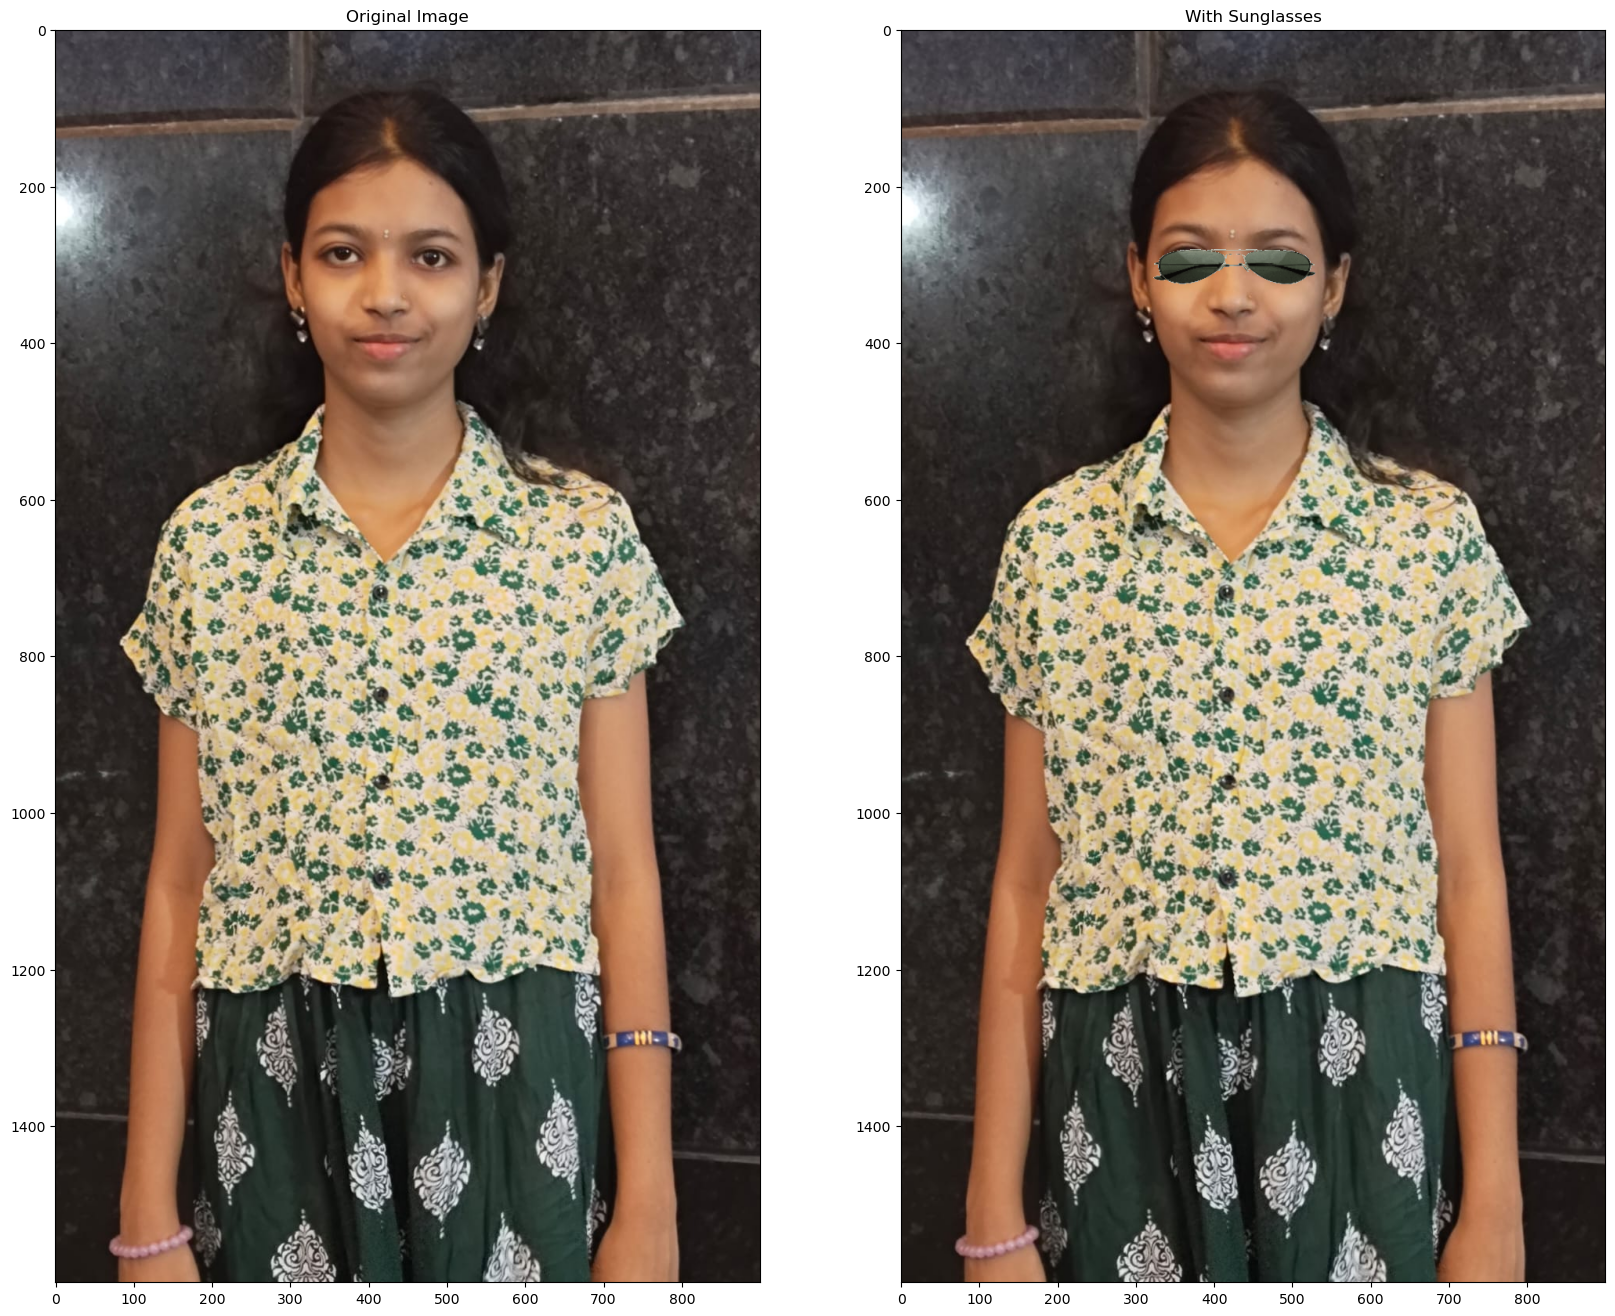

In [23]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[275:330, 315:535] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20])
plt.subplot(121); plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image")
plt.subplot(122); plt.imshow(faceWithGlassesArithmetic[:,:,::-1]); plt.title("With Sunglasses")